# Customer Churn Prediction — Model Evaluation

## Objective
The objective of this notebook is to evaluate and compare the machine-learning models developed for predicting customer churn.

## Models to Compare
- Logistic Regression
- Decision Tree

## Evaluation Metrics
- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

## Expected Outcome
Identify the most suitable model for predicting customer churn based on its evaluation results.

In [8]:

# Day 7: Final Model Comparison

from pathlib import Path
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")


Libraries imported successfully!


In [9]:

# Find the project folder automatically

current_path = Path.cwd()

possible_paths = [
    current_path,
    current_path.parent,
    current_path.parent.parent
]

project_folder = None

for path in possible_paths:
    if (path / "models").is_dir() and (path / "data").is_dir():
        project_folder = path
        break

if project_folder is None:
    raise FileNotFoundError(
        "Project folder not found. Check the notebook location."
    )

models_folder = project_folder / "models"
data_folder = project_folder / "data" / "processed" / "model_inputs"

print("Project folder:", project_folder)
print("Models folder exists:", models_folder.exists())
print("Test data folder exists:", data_folder.exists())
print("\nSaved models:")

for file in models_folder.iterdir():
    print(file.name)


Project folder: c:\Users\Dell\OneDrive\Desktop\Customer-Churn-Prediction
Models folder exists: True
Test data folder exists: True

Saved models:
decision_tree_model.joblib
logistic_regression_model.joblib


In [10]:

# Load the two saved models

logistic_model = joblib.load(
    models_folder / "logistic_regression_model.joblib"
)

decision_tree_model = joblib.load(
    models_folder / "decision_tree_model.joblib"
)

print("Logistic Regression model loaded!")
print("Decision Tree model loaded!")


Logistic Regression model loaded!
Decision Tree model loaded!


In [11]:

# Load test data

X_test = pd.read_csv(data_folder / "X_test.csv")
y_test = pd.read_csv(data_folder / "y_test.csv")

# Convert the target to a one-dimensional series
y_test = y_test.squeeze()

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nFirst five target values:")
print(y_test.head())


X_test shape: (1409, 20)
y_test shape: (1409,)

First five target values:
0    0
1    0
2    0
3    0
4    0
Name: Churn Label, dtype: int64


In [13]:


# Inspect and clean blank spaces in the test data

print("X_test shape:", X_test.shape)

# Convert cells containing only spaces into missing values
X_test = X_test.replace(r'^\s*$', np.nan, regex=True)

print("Blank spaces cleaned!")
print("\nMissing values in X_test:")
print(X_test.isna().sum()[X_test.isna().sum() > 0])


X_test shape: (1409, 20)
Blank spaces cleaned!

Missing values in X_test:
Total Charges    3
dtype: int64


In [14]:

# Predict customer churn using both models

logistic_predictions = logistic_model.predict(X_test)
decision_tree_predictions = decision_tree_model.predict(X_test)

print("Predictions generated successfully!")
print("Logistic Regression predictions:", len(logistic_predictions))
print("Decision Tree predictions:", len(decision_tree_predictions))


Predictions generated successfully!
Logistic Regression predictions: 1409
Decision Tree predictions: 1409


In [15]:

# Day 7: Compare model performance

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

def calculate_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, y_pred, zero_division=0
        )
    }

comparison = pd.DataFrame({
    "Logistic Regression": calculate_metrics(
        y_test, logistic_predictions
    ),
    "Decision Tree": calculate_metrics(
        y_test, decision_tree_predictions
    )
})

print("MODEL PERFORMANCE COMPARISON")
display(comparison.round(4))


MODEL PERFORMANCE COMPARISON


,Logistic Regression,Decision Tree
Accuracy,0.8041,0.7268
Precision,0.6467,0.4861
Recall,0.5775,0.5134
F1-score,0.6102,0.4993


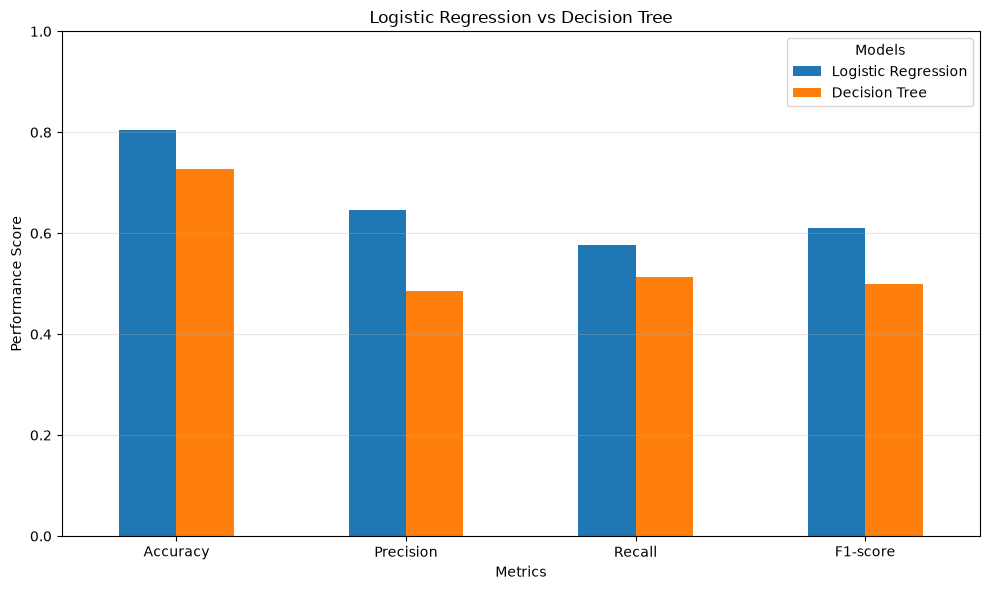

In [16]:

# Compare the models using a bar chart

comparison.plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Logistic Regression vs Decision Tree")
plt.ylabel("Performance Score")
plt.xlabel("Metrics")
plt.legend(title="Models")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


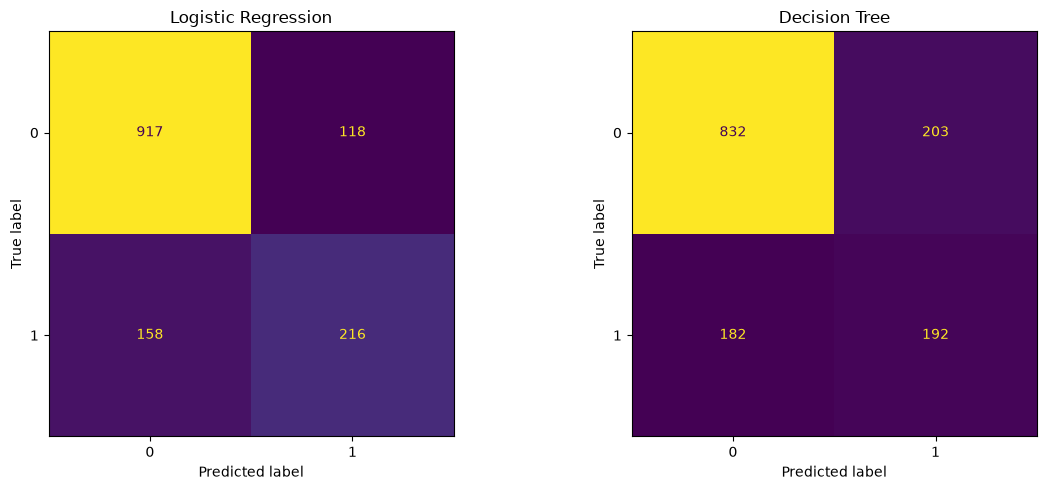

In [17]:

# Compare confusion matrices for both models

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(
    confusion_matrix(y_test, logistic_predictions)
).plot(ax=axes[0], colorbar=False)

axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay(
    confusion_matrix(y_test, decision_tree_predictions)
).plot(ax=axes[1], colorbar=False)

axes[1].set_title("Decision Tree")

plt.tight_layout()
plt.show()


In [18]:

# Identify the model with the highest F1-score

best_model_name = comparison.loc["F1-score"].idxmax()
best_f1_score = comparison.loc["F1-score"].max()

print("Best model based on F1-score:", best_model_name)
print("F1-score:", round(best_f1_score, 4))

print("\nFinal observation:")
print(
    f"{best_model_name} achieved the higher F1-score "
    "on the test dataset."
)


Best model based on F1-score: Logistic Regression
F1-score: 0.6102

Final observation:
Logistic Regression achieved the higher F1-score on the test dataset.


In [19]:

# Save model comparison results

results_path = project_folder / "model_comparison_results.csv"

comparison.to_csv(results_path)

print("Comparison results saved successfully!")
print("Saved at:", results_path)


Comparison results saved successfully!
Saved at: c:\Users\Dell\OneDrive\Desktop\Customer-Churn-Prediction\model_comparison_results.csv


# Day 7: Final Model Comparison

## Objective
To compare Logistic Regression and Decision Tree models using the same test dataset.

## Observations
1. Both models were evaluated using accuracy, precision, recall, and F1-score.
2. The confusion matrices showed the correct and incorrect predictions made by each model.
3. Recall helped us understand how many actual churn customers were identified.
4. The F1-score helped compare the balance between precision and recall.
5. The better model was identified by comparing its performance metrics.

## Conclusion
Logistic Regression and Decision Tree were evaluated on the same test dataset. Their performance metrics and confusion matrices were compared to identify the more suitable model for customer churn prediction. The final selection should consider recall, F1-score, and the business objective.